In [1]:
!pip install pandas

In [2]:
!pip install matplotlib

In [4]:
import pandas as pd
import kagglehub
import glob
import os

# 1. Download the full dataset folder
dataset_path = kagglehub.dataset_download("aamir28/student-sleep-screen-time-and-academic-performance")

# 2. Automatically find any CSV file inside that folder
csv_files = glob.glob(os.path.join(dataset_path, "*.csv"))

if csv_files:
    # 3. Load the first CSV file found
    df = pd.read_csv(csv_files[0])
    print("Successfully loaded:", os.path.basename(csv_files[0]))
    print(df.head())
else:
    print("No CSV files found in the dataset folder.")

100%|██████████| 15.8k/15.8k [00:00<00:00, 7.88MB/s]

Extracting files...
Successfully loaded: student_sleep_screen_time_academic_performance.csv
  student_id  age  gender  year_of_study   major_category  \
0    STU2001   21    Male              3       Humanities   
1    STU2002   20  Female              2             STEM   
2    STU2003   20    Male              4  Social Sciences   
3    STU2004   22       F              1       Humanities   
4    STU2005   23  Female              4  Social Sciences   

         residence_type    chronotype  avg_bedtime_hour  \
0           With Family    Early Bird              22.3   
1             Dormitory  Intermediate              23.1   
2           With Family  Intermediate              23.4   
3  Off-campus Apartment     Night Owl               0.9   
4  Off-campus Apartment    Early Bird              23.4   

   avg_sleep_hours_weekday  weekend_sleep_delta_hours  ...  naps_per_week  \
0                      7.6                        2.0  ...              0   
1                      5.9      

In [5]:
# Display first five rows
print(df.head())

# Number of rows and columns
print(df.shape)

# Column names and data types
print(df.info())

# Summary statistics
print(df.describe())

  student_id  age  gender  year_of_study   major_category  \
0    STU2001   21    Male              3       Humanities   
1    STU2002   20  Female              2             STEM   
2    STU2003   20    Male              4  Social Sciences   
3    STU2004   22       F              1       Humanities   
4    STU2005   23  Female              4  Social Sciences   

         residence_type    chronotype  avg_bedtime_hour  \
0           With Family    Early Bird              22.3   
1             Dormitory  Intermediate              23.1   
2           With Family  Intermediate              23.4   
3  Off-campus Apartment     Night Owl               0.9   
4  Off-campus Apartment    Early Bird              23.4   

   avg_sleep_hours_weekday  weekend_sleep_delta_hours  ...  naps_per_week  \
0                      7.6                        2.0  ...              0   
1                      5.9                        2.7  ...              3   
2                      8.4                     

In [6]:
# Missing values in each column
print(df.isnull().sum())

# Total duplicate rows
print(df.duplicated().sum())

student_id                    0
age                           0
gender                        0
year_of_study                 0
major_category                0
residence_type                0
chronotype                    0
avg_bedtime_hour              0
avg_sleep_hours_weekday       0
weekend_sleep_delta_hours     0
pre_sleep_screen_time_min     0
daily_screen_time_hours       0
primary_device                0
device_free_before_bed        9
caffeine_drinks_per_day       0
naps_per_week                 0
sleep_quality_score           6
exercise_days_per_week        0
energy_level                 15
concentration_difficulty     14
weekly_study_hours            0
class_attendance_percent      0
has_part_time_job             0
semester_type                 0
cgpa                          7
dtype: int64
0


Using Colab cache for faster access to the 'student-sleep-screen-time-and-academic-performance' dataset.


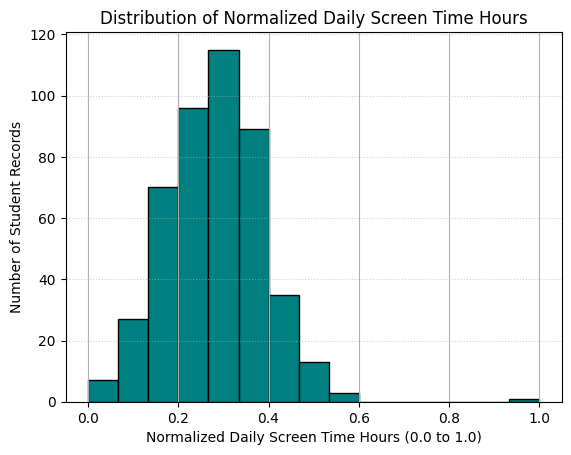

In [9]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from kagglehub import KaggleDatasetAdapter

# 1. Re-initialize and securely load the clean student sleep dataset package
df = kagglehub.dataset_load(
    adapter=KaggleDatasetAdapter.PANDAS,
    handle="aamir28/student-sleep-screen-time-and-academic-performance",
    path="student_sleep_screen_time_academic_performance.csv"
)

# 2. Drop the minor missing rows (under 3% baseline data) to match your previous step
columns_with_missing = ['device_free_before_bed', 'sleep_quality_score', 'energy_level', 'concentration_difficulty', 'cgpa']
df_clean = df.dropna(subset=columns_with_missing).copy()

# 3. List target numerical columns for scaling
num_cols = [
    'age', 'avg_sleep_hours_weekday', 'weekend_sleep_delta_hours',
    'pre_sleep_screen_time_min', 'daily_screen_time_hours',
    'caffeine_drinks_per_day', 'naps_per_week', 'sleep_quality_score',
    'exercise_days_per_week', 'weekly_study_hours',
    'class_attendance_percent', 'cgpa'
]

# 4. Perform Min-Max Normalization (Scale between 0 and 1)
df_normalized = df_clean.copy()
df_normalized[num_cols] = (df_clean[num_cols] - df_clean[num_cols].min()) / (df_clean[num_cols].max() - df_clean[num_cols].min())

# ==========================================
# 5. GENERATE HISTOGRAM (Using your code format)
# ==========================================
target_col = "daily_screen_time_hours"

df_normalized[target_col].hist(bins=15, edgecolor='black', color='teal')

plt.title(f"Distribution of Normalized {target_col.replace('_', ' ').title()}")
plt.xlabel(f"Normalized {target_col.replace('_', ' ').title()} (0.0 to 1.0)")
plt.ylabel("Number of Student Records")
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.show()


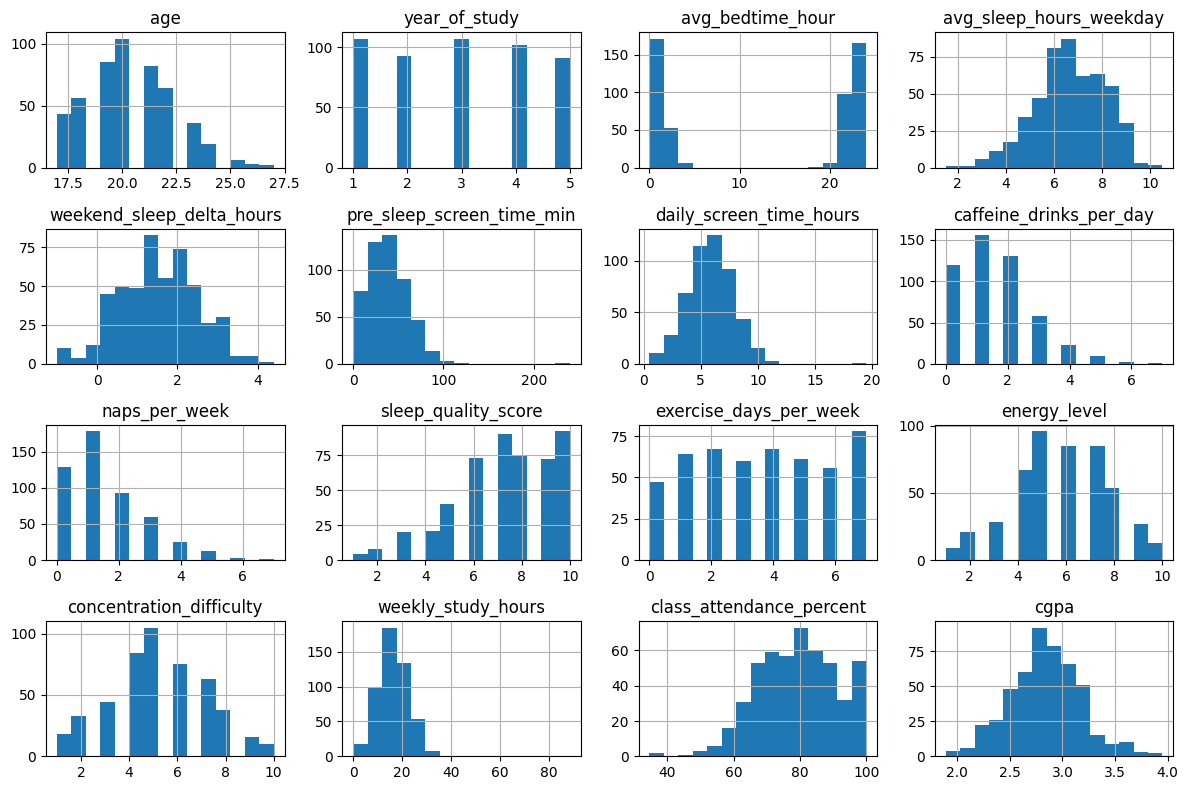

In [10]:
df.hist(figsize=(12, 8), bins=15)
plt.tight_layout()
plt.show()

In [11]:
correlation = df.select_dtypes(
    include="number"
).corr()

print(correlation)

                                age  year_of_study  avg_bedtime_hour  \
age                        1.000000      -0.052921         -0.004325   
year_of_study             -0.052921       1.000000         -0.061129   
avg_bedtime_hour          -0.004325      -0.061129          1.000000   
avg_sleep_hours_weekday    0.051960      -0.004380          0.348848   
weekend_sleep_delta_hours -0.026313      -0.063006         -0.175155   
pre_sleep_screen_time_min -0.069551       0.110610         -0.347687   
daily_screen_time_hours   -0.006242      -0.026253         -0.015230   
caffeine_drinks_per_day   -0.018359      -0.034099         -0.033549   
naps_per_week             -0.031363       0.017709         -0.045618   
sleep_quality_score        0.029400      -0.052440          0.295189   
exercise_days_per_week    -0.054984       0.084099         -0.038679   
energy_level               0.069024       0.030366          0.139857   
concentration_difficulty  -0.134817      -0.039931         -0.16

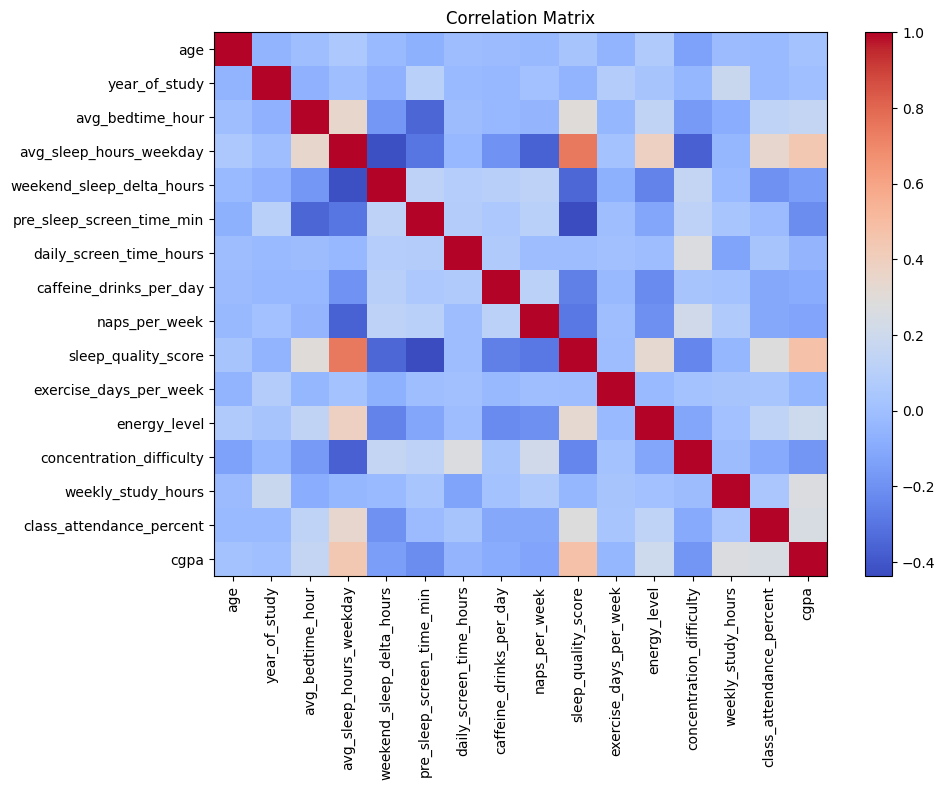

In [12]:
plt.figure(figsize=(10, 8))

plt.imshow(correlation, cmap="coolwarm", aspect="auto")
plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)
plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()